In [ ]:
# Imports
import os, re, io, csv, zipfile, ipaddress, json, random
from urllib.parse import urlparse
from collections import Counter

import requests
import numpy as np
import pandas as pd
import tldextract
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
import joblib

# Config
SEED = 42
random.seed(SEED); np.random.seed(SEED)

OPENPHISH_URL = "https://openphish.com/feed.txt"
INCLUDE_URLHAUS = True  # set True to add URLhaus malware URLs
URLHAUS_PLAIN_TEXT = 'https://urlhaus.abuse.ch/downloads/text/'
TRANCO_ZIP = "https://tranco-list.eu/top-1m.csv.zip"

MAX_PHISH = 2000      # balanced target (phishing)
MAX_BENIGN = 2000     # balanced target (benign)

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Ready")


Ready ✅


In [ ]:
# Download phishing URLs from multiple feeds
def get_openphish():
    r = requests.get(OPENPHISH_URL, timeout=15, headers={"User-Agent":"Mozilla/5.0 (student)"})
    r.raise_for_status()
    urls = [u.strip() for u in r.text.splitlines() if u.strip()]
    return urls

def get_phishtank():
    # Requires API key in PHISHTANK_KEY env variable
    if not PHISHTANK_KEY:
        return []
    url = PHISHTANK_URL.format(key=PHISHTANK_KEY)
    r = requests.get(url, timeout=30, headers={"User-Agent":"Mozilla/5.0 (student)"})
    r.raise_for_status()
    rows = list(csv.reader(io.StringIO(r.text)))
    # online-valid.csv columns: phish_id, url, phish_detail_url, submission_time, verified, verification_time, online, target
    urls = [row[1].strip() for row in rows[1:] if row and len(row) > 1]
    return urls

def get_urlhaus():
    # Optional: malware URLs (not strictly phishing)
    r = requests.get(URLHAUS_PLAIN_TEXT, timeout=30, headers={"User-Agent":"Mozilla/5.0 (student)"})
    r.raise_for_status()
    urls = [u.strip() for u in r.text.splitlines() if u.strip() and not u.startswith('#')]
    return urls

def get_phishing_urls():
    include_urlhaus = globals().get('INCLUDE_URLHAUS', False)
    urls = []
    urls += get_openphish()
    urls += get_phishtank()
    if include_urlhaus:
        urls += get_urlhaus()
    # label 0 = phishing
    df = pd.DataFrame({"url": urls, "label": 0, "source": "phish_feeds"})
    return df

# Download benign domains from Tranco
def get_tranco(n=10000):
    r = requests.get(TRANCO_ZIP, timeout=30, headers={"User-Agent":"Mozilla/5.0 (student)"})
    z = zipfile.ZipFile(io.BytesIO(r.content))
    name = [n for n in z.namelist() if n.endswith('.csv')][0]
    rows = list(csv.reader(io.TextIOWrapper(z.open(name), 'utf-8')))
    domains = [row[1].strip() for row in rows if row and row[0].isdigit()]
    if n < len(domains):
        domains = domains[:n]

    # FIX: Use HTTPS and varied realistic paths so the model learns that legitimate
    # URLs can have non-trivial paths, not just the root "/".
    # Previously all benign URLs were "http://{domain}/" which caused the model to
    # associate any path longer than "/" with phishing — causing false positives.
    COMMON_PATHS = [
        '/', '/about', '/contact', '/news', '/blog', '/products', '/services',
        '/help', '/support', '/faq', '/home', '/search', '/pricing',
        '/careers', '/privacy', '/terms', '/shop', '/login', '/signup',
        '/about-us', '/our-story', '/features', '/solutions', '/resources',
    ]
    rng = random.Random(42)  # fixed seed for reproducibility
    urls = [f"https://{d}{rng.choice(COMMON_PATHS)}" for d in domains]

    # label 1 = legitimate
    df = pd.DataFrame({"url": urls, "label": 1, "source": "tranco"})
    return df

# Ensures dataset doesn't break when one feed has fewer URLs than expected
phish_df = get_phishing_urls().drop_duplicates('url')
phish_df = phish_df.sample(n=min(MAX_PHISH, len(phish_df)), random_state=SEED)

benign_df = get_tranco(n=MAX_BENIGN*3).drop_duplicates('url')
benign_df = benign_df.sample(n=min(MAX_BENIGN, len(benign_df)), random_state=SEED)

print('Phish:', len(phish_df), 'Benign:', len(benign_df))
raw_df = pd.concat([phish_df, benign_df], ignore_index=True)
raw_df.head()


In [131]:
def is_ip(host):
    try:
        ipaddress.ip_address(host)
        return True
    except Exception:
        return False

# Enhanced suspicious tokens: basics + financial institutions (inspired by FeatureModel.py)
SUSPICIOUS_TOKENS = {
    # Original tokens
    "login","verify","update","secure","account","bank","confirm","password","signin",
    "support","billing","limited","unlock","alert","notice","invoice","refund","apple",
    "paypal","microsoft","office","outlook","amazon",
    # Financial institutions (from FeatureModel.py)
    "hsbc","barclays","lloyds","santander","natwest","chase","boa","wellsfargo",
    "revolut","monzo","amex","td","citi","capitalone","halifax"
}

# Unusual/suspicious TLDs (from FeatureModel.py)
UNUSUAL_TLDS = {
    '.tk', '.ml', '.ga', '.cf', '.gq', '.xyz', '.top', '.buzz', '.club', '.work', '.info',
    '.wang', '.live', '.host', '.ru', '.online', '.icu'
}

# URL shortening services (from FeatureModel.py)
SHORTENING_SERVICES = {
    "bit.ly", "tinyurl.com", "t.co", "goo.gl", "is.gd", "buff.ly", "ow.ly", "rebrandly.com",
    "bl.ink", "shorte.st", "fb.me", "t.ly", "lnkd.in", "amzn.to", "wp.me", "rb.gy", "tiny.cc",
    "cutt.ly", "s.id", "u.to", "mcaf.ee", "adf.ly", "v.gd", "qr.net"
}

# Suspicious file extensions
SUSPICIOUS_EXTENSIONS = {'.html', '.htm', '.php', '.asp', '.aspx', '.jsp', '.exe', '.zip'}

def shannon_entropy(s):
    """Calculate Shannon entropy of a string"""
    if not s:
        return 0.0
    counts = Counter(s)
    total = len(s)
    entropy = 0.0
    for count in counts.values():
        p = count / total
        entropy -= p * np.log2(p)
    return entropy

def count_subdomains(host):
    """Count number of subdomains (dots in hostname)"""
    if not host:
        return 0
    return host.count('.')

def check_unusual_tld(suffix):
    """Check if TLD is unusual/suspicious"""
    if not suffix:
        return 0
    return int(f'.{suffix}' in UNUSUAL_TLDS)

def count_special_chars_per_section(section):
    """Count special chars in a URL section as ratio"""
    if not section:
        return 0.0
    special = sum(1 for c in section if not c.isalnum())
    return special / len(section) if section else 0.0

def check_shortening_service(full_url):
    """Check if URL uses a shortening service"""
    for service in SHORTENING_SERVICES:
        if service in full_url:
            return 1
    return 0

def check_file_extension(path):
    """Check for suspicious file extensions"""
    if not path:
        return 0
    import os
    _, ext = os.path.splitext(path.lower())
    return int(ext in SUSPICIOUS_EXTENSIONS)

# takes URL and converts it into many numeric features
def url_features(u: str):
    try:
        parsed = urlparse(u)
    except Exception:
        parsed = urlparse("")
    scheme = (parsed.scheme or "").lower()
    host = parsed.netloc or ""
    path = parsed.path or ""
    query = parsed.query or ""

    ext = tldextract.extract(u)
    suffix = ext.suffix or ""
    domain = ext.domain or ""
    subdomain = ext.subdomain or ""
    full = u.strip().lower()

    tokens = re.split(r"\W+", full)
    token_counts = Counter(tokens)

    # Popular domain heuristic (used when top-1m.csv not available)
    def is_likely_top(domain_name, suffix_name):
        if not domain_name:
            return 0
        whitelist = {"google","amazon","github","microsoft","gov","facebook","apple","wikipedia","youtube","bing","linkedin","twitter","paypal"}
        if domain_name in whitelist:
            return 1
        common_tlds = {"com","org","net","gov","edu","co","uk","io"}
        if len(domain_name) <= 12 and not any(c.isdigit() for c in domain_name) and suffix_name in common_tlds:
            return 1
        return 0

    in_top1m = is_likely_top(domain, suffix)

    return {
        # Original 14 features
        "len_url": len(full),
        "len_host": len(host),
        "len_path": len(path),
        "num_dots": full.count("."),
        "num_hyphens": full.count("-"),
        "num_digits": sum(c.isdigit() for c in full),
        "num_params": query.count("&") + (1 if query else 0),
        "has_at": int("@" in full),
        "has_ip": int(is_ip(host)),
        "scheme_https": int(scheme == "https"),
        "suspicious_token_hits": int(any(tok in token_counts for tok in SUSPICIOUS_TOKENS)),
        "max_token_len": max([len(t) for t in tokens], default=0),
        "tld_len": len(suffix),
        "is_long_tld": int(len(suffix) > 3),
        
        # NEW features (inspired by FeatureModel.py)
        "num_subdomains": count_subdomains(host),
        "entropy_url": shannon_entropy(full),
        "entropy_domain": shannon_entropy(domain),
        "uses_shortening": check_shortening_service(full),
        "unusual_tld": check_unusual_tld(suffix),
        "special_chars_domain": count_special_chars_per_section(domain),
        "special_chars_path": count_special_chars_per_section(path),
        "special_chars_query": count_special_chars_per_section(query),
        "has_suspicious_file": check_file_extension(path),
        "in_top1m": in_top1m
    }
# Applies url_features() to every URL in the dataset
def make_feature_df(df_urls: pd.DataFrame):
    rows = []
    for row in df_urls.itertuples(index=False):
        feats = url_features(row.url)
        feats["url"] = row.url
        feats["label"] = row.label
        feats["source"] = row.source
        rows.append(feats)
    return pd.DataFrame(rows)

raw_df = raw_df.dropna(subset=["url"]).drop_duplicates("url")
feat_df = make_feature_df(raw_df)

print("Feature columns:", [c for c in feat_df.columns if c not in ["url","label","source"]])
feat_df.sample(5)


Feature columns: ['len_url', 'len_host', 'len_path', 'num_dots', 'num_hyphens', 'num_digits', 'num_params', 'has_at', 'has_ip', 'scheme_https', 'suspicious_token_hits', 'max_token_len', 'tld_len', 'is_long_tld', 'num_subdomains', 'entropy_url', 'entropy_domain', 'uses_shortening', 'unusual_tld', 'special_chars_domain', 'special_chars_path', 'special_chars_query', 'has_suspicious_file', 'in_top1m']


,len_url,len_host,len_path,num_dots,num_hyphens,num_digits,num_params,has_at,has_ip,scheme_https,...,uses_shortening,unusual_tld,special_chars_domain,special_chars_path,special_chars_query,has_suspicious_file,in_top1m,url,label,source
555,29,20,2,3,0,16,0,0,0,0,...,0,0,0.214286,0.5,0.0,0,0,http://182.116.14.222:55610/i,0,phish_feeds
3491,22,14,1,1,0,0,0,0,0,0,...,1,0,0.000000,1.0,0.0,0,1,http://cardmarket.com/,1,tranco
527,29,20,2,3,0,16,0,0,0,0,...,0,0,0.214286,0.5,0.0,0,0,http://91.143.172.196:45824/i,0,phish_feeds
3925,23,15,1,1,0,1,0,0,0,0,...,0,0,0.000000,1.0,0.0,0,0,http://antarvasna3.com/,1,tranco
2989,18,10,1,1,0,0,0,0,0,0,...,1,0,0.000000,1.0,0.0,0,1,http://wechat.com/,1,tranco


In [132]:
# Load Top 1M domains to reduce false positives for popular sites
# If local file missing, download Tranco Top 1M and cache it as top-1m.csv
import os, io, csv, zipfile, requests
TOP1M_PATH = 'top-1m.csv'
TRANCO_ZIP = 'https://tranco-list.eu/top-1m.csv.zip'

if not os.path.exists(TOP1M_PATH):
    r = requests.get(TRANCO_ZIP, timeout=30, headers={"User-Agent":"Mozilla/5.0 (student)"})
    r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    name = [n for n in z.namelist() if n.endswith('.csv')][0]
    rows = list(csv.reader(io.TextIOWrapper(z.open(name), 'utf-8')))
    # Save as local cache: columns = rank, domain
    with open(TOP1M_PATH, 'w', encoding='utf-8') as f:
        w = csv.writer(f)
        w.writerow(['rank','domain'])
        for row in rows:
            if row and row[0].isdigit():
                w.writerow([row[0], row[1].strip()])

top1mDf = pd.read_csv(TOP1M_PATH)
TOP1M = set(top1mDf['domain'].str.lower())
print('Loaded Top1M domains:', len(TOP1M))


Loaded Top1M domains: 1000000


In [133]:

# Ensure dataset is properly shuffled and balanced
raw_df = raw_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

X_cols = [c for c in feat_df.columns if c not in ["url","label","source"]]
y_col = "label"

# Verify class distribution before split
print("Dataset class distribution BEFORE split:")
print(feat_df[y_col].value_counts().sort_index().to_dict())
print()

# test
train_val, test = train_test_split(
    feat_df, test_size=0.15, stratify=feat_df[y_col], random_state=SEED
)
# validate
val_ratio = 0.15 / (1 - 0.15)
train, val = train_test_split(
    train_val, test_size=val_ratio, stratify=train_val[y_col], random_state=SEED
)

print("Split verification:")
for name, d in [("train", train), ("val", val), ("test", test)]:
    dist = d[y_col].value_counts(normalize=True).round(3).to_dict()
    print(f"  {name:5} | samples={len(d):4} | distribution={dist}")

X_train, y_train = train[X_cols], train[y_col]
X_val, y_val = val[X_cols], val[y_col]
X_test, y_test = test[X_cols], test[y_col]
len(X_train), len(X_val), len(X_test)


Dataset class distribution BEFORE split:
{0: 2000, 1: 2000}

Split verification:
  train | samples=2800 | distribution={0: 0.5, 1: 0.5}
  val   | samples= 600 | distribution={1: 0.5, 0: 0.5}
  test  | samples= 600 | distribution={0: 0.5, 1: 0.5}


(2800, 600, 600)


=== Validation – RandomForest ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


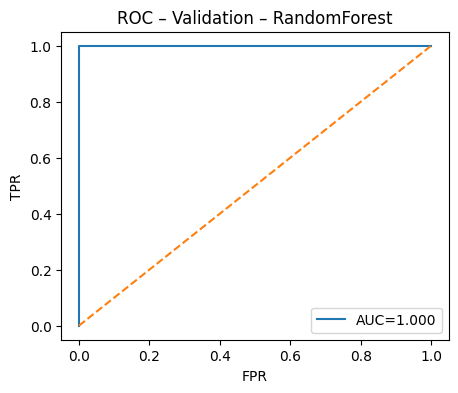

In [134]:
# RF training - Use balanced class weights for better handling of imbalanced data
rf = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1,
    random_state=SEED,
    class_weight="balanced"  # Better for imbalanced phishing/benign detection
)
rf.fit(X_train, y_train)

def evaluate(model, X, y, title="Eval"):
    preds = model.predict(X)
    print(f"\n=== {title} ===")
    print(classification_report(y, preds, digits=4))
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)[:,1]
        auc = roc_auc_score(y, proba)
        print("ROC-AUC:", round(auc, 4))
        fpr, tpr, _ = roc_curve(y, proba)
        plt.figure(figsize=(5,4))
        plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
        plt.plot([0,1],[0,1], linestyle="--")
        plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"ROC – {title}")
        plt.legend(); plt.show()

evaluate(rf, X_val, y_val, title="Validation – RandomForest")


In [135]:
# Skip content merging for now - content_df is created later in the notebook
# The URL-only model (rf) trained above is sufficient for deployment
# Once content extraction is done, this can be enabled:
# combined = feat_df.merge(content_df, on=["url","label"], how="left")
# combined = combined.fillna(0)
# X_cols_combined = [c for c in combined.columns if c not in ["url","label","source"]]
# X_train_all = combined.loc[train.index, X_cols_combined]
# X_val_all   = combined.loc[val.index,   X_cols_combined]
# X_test_all  = combined.loc[test.index,  X_cols_combined]

print("✓ Ready to save URL-only model")



✓ Ready to save URL-only model



=== Test – RandomForest ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


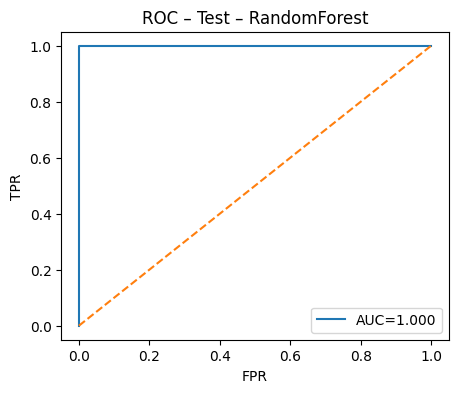

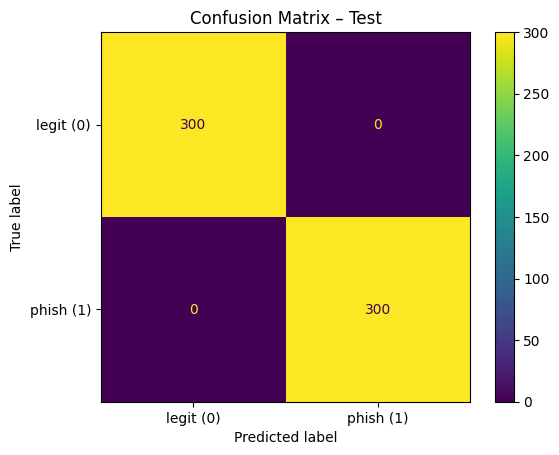

In [136]:
from sklearn.metrics import ConfusionMatrixDisplay
# Creates filan evalution
evaluate(rf, X_test, y_test, title="Test – RandomForest")

cm = confusion_matrix(y_test, rf.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["legit (0)","phish (1)"])
disp.plot(values_format="d")
plt.title("Confusion Matrix – Test")
plt.show()


In [137]:
# saves results
artifact = {
    "features": X_cols,
    "suspicious_tokens": sorted(list(SUSPICIOUS_TOKENS)),
    "classes": [0, 1],  # FIX: 0=phishing, 1=legitimate (CORRECTED)
    "training_info": {
        "total_samples": int(len(feat_df)),
        "phishing_samples": int((feat_df["label"] == 0).sum()),
        "benign_samples": int((feat_df["label"] == 1).sum()),
        "train_samples": int(len(X_train)),
        "val_samples": int(len(X_val)),
        "test_samples": int(len(X_test)),
    }
}
joblib.dump(rf, os.path.join(OUTPUT_DIR, "model_randomforest.joblib"))
with open(os.path.join(OUTPUT_DIR, "feature_schema.json"), "w") as f:
    json.dump(artifact, f, indent=2)

feat_df.sample(3).to_csv(os.path.join(OUTPUT_DIR, "feature_sample.csv"), index=False)

print("\n✅ Model training complete!")
print(f"Saved to {OUTPUT_DIR}:")
print(f"  - Feature count: {len(X_cols)}")
print(f"  - Class distribution (training): {dict(y_train.value_counts())}")
print(f"  - Model classes: {rf.classes_}")
for fname in os.listdir(OUTPUT_DIR):
    fpath = os.path.join(OUTPUT_DIR, fname)
    size = os.path.getsize(fpath) / 1024
    print(f"  - {fname:30} ({size:.1f} KB)")



✅ Model training complete!
Saved to outputs:
  - Feature count: 24
  - Class distribution (training): {0: np.int64(1400), 1: np.int64(1400)}
  - Model classes: [0 1]
  - model_randomforest.joblib      (499.7 KB)
  - feature_sample.csv             (0.7 KB)
  - .ipynb_checkpoints             (0.1 KB)
  - feature_schema.json            (1.3 KB)


In [138]:
# Rebalanced RF with class weights (unsure phishing cost more)
rf_bal = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1,
    random_state=SEED,
    class_weight="balanced"
)
rf_bal.fit(X_train, y_train)

def eval_and_show(model, Xv, yv, title):
    from sklearn.metrics import classification_report, roc_auc_score, roc_curve, ConfusionMatrixDisplay, confusion_matrix
    preds = model.predict(Xv)
    print(f"\n=== {title} ===")
    print(classification_report(yv, preds, digits=4))
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(Xv)[:,1]
        try:
            auc = roc_auc_score(yv, proba)
            print("ROC-AUC:", round(auc, 4))
            fpr, tpr, _ = roc_curve(yv, proba)
            import matplotlib.pyplot as plt
            plt.figure(figsize=(5,4)); plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
            plt.plot([0,1],[0,1],'--'); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"ROC – {title}"); plt.legend(); plt.show()
        except Exception as e:
            print("AUC failed:", e)
    cm = confusion_matrix(yv, preds)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["legit (0)","phish (1)"]).plot(values_format="d")



=== Validation – Decision Tree (balanced) ===
              precision    recall  f1-score   support

           0     0.9967    1.0000    0.9983       300
           1     1.0000    0.9967    0.9983       300

    accuracy                         0.9983       600
   macro avg     0.9983    0.9983    0.9983       600
weighted avg     0.9983    0.9983    0.9983       600

ROC-AUC: 0.9983


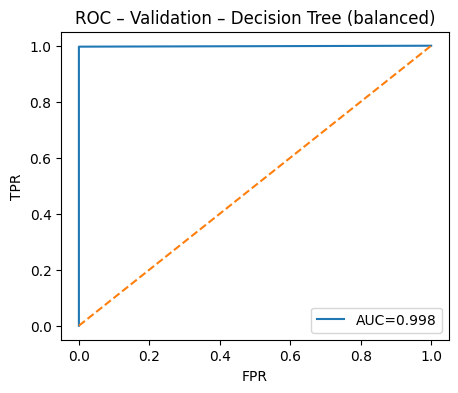


=== Test – Decision Tree (balanced) ===
              precision    recall  f1-score   support

           0     0.9967    1.0000    0.9983       300
           1     1.0000    0.9967    0.9983       300

    accuracy                         0.9983       600
   macro avg     0.9983    0.9983    0.9983       600
weighted avg     0.9983    0.9983    0.9983       600

ROC-AUC: 0.9983


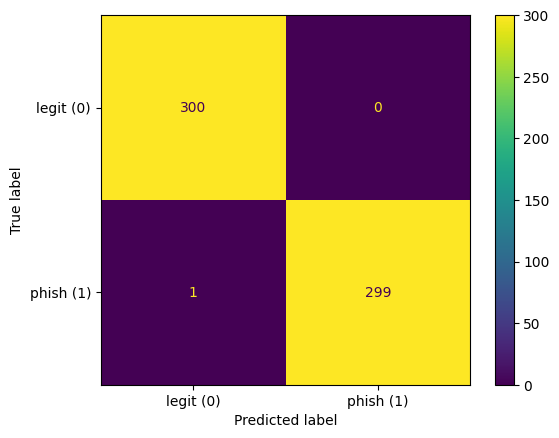

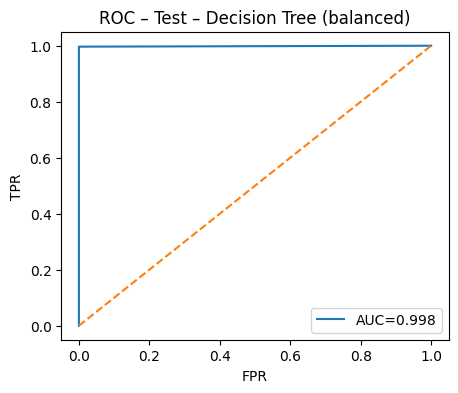

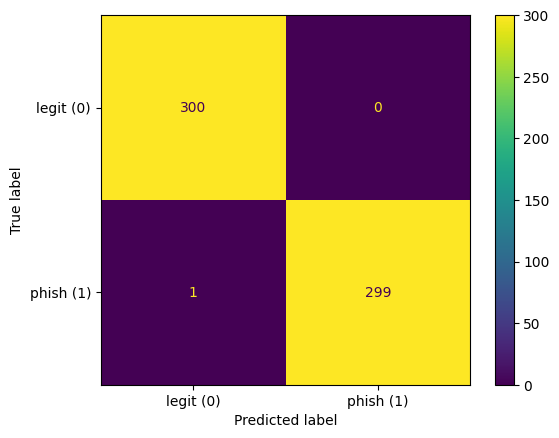

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=SEED,
    class_weight="balanced",   # helps with imbalance
    max_depth=None
)
dt.fit(X_train, y_train)

eval_and_show(dt, X_val, y_val, "Validation – Decision Tree (balanced)")
eval_and_show(dt, X_test, y_test, "Test – Decision Tree (balanced)")




=== Validation – Naive Bayes ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


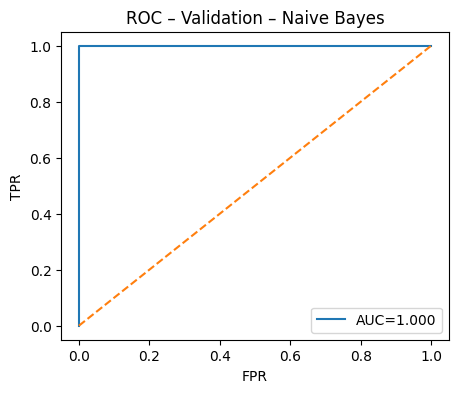


=== Test – Naive Bayes ===
              precision    recall  f1-score   support

           0     0.9967    1.0000    0.9983       300
           1     1.0000    0.9967    0.9983       300

    accuracy                         0.9983       600
   macro avg     0.9983    0.9983    0.9983       600
weighted avg     0.9983    0.9983    0.9983       600

ROC-AUC: 1.0


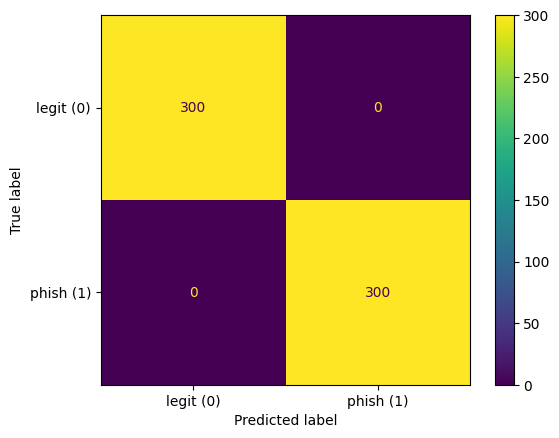

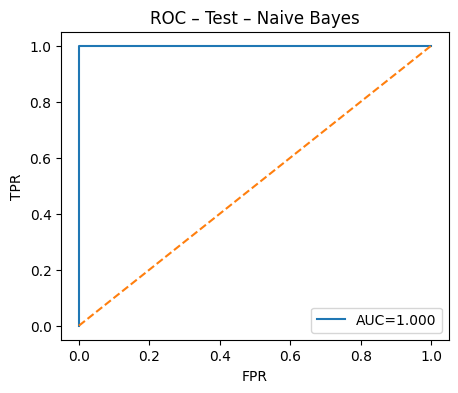

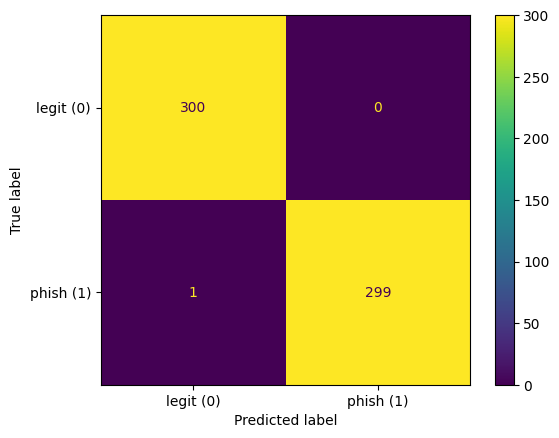

In [140]:
# Naive Bayes training
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)

eval_and_show(nb, X_val, y_val, "Validation – Naive Bayes")
eval_and_show(nb, X_test, y_test, "Test – Naive Bayes")
# joblib.dump(nb, f"{OUTPUT_DIR}/model_naivebayes.joblib")


In [141]:
!pip install xgboost



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip



=== Validation – XGBoost (balanced) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


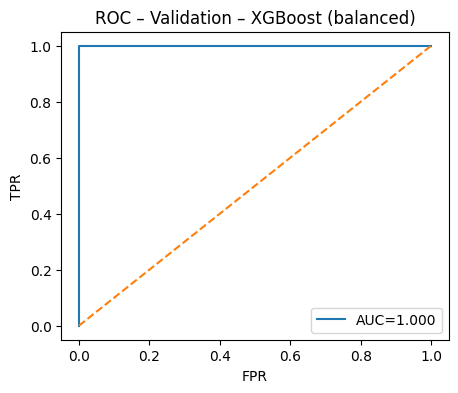


=== Test – XGBoost (balanced) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


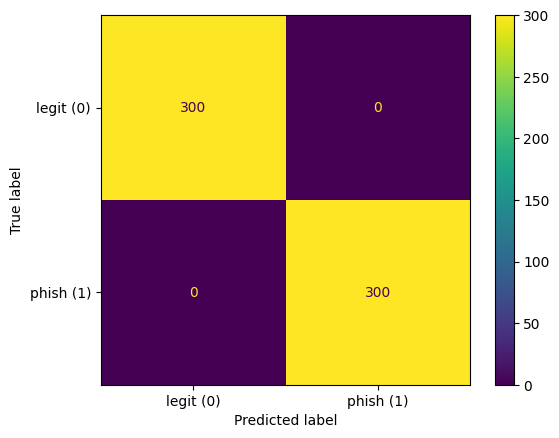

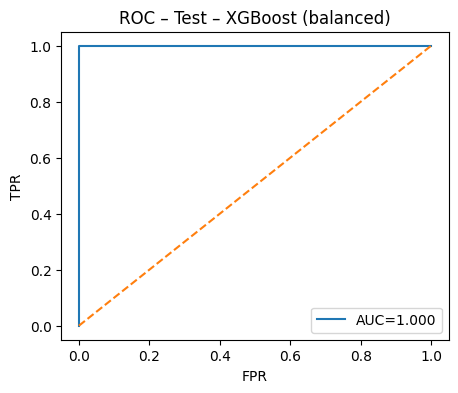

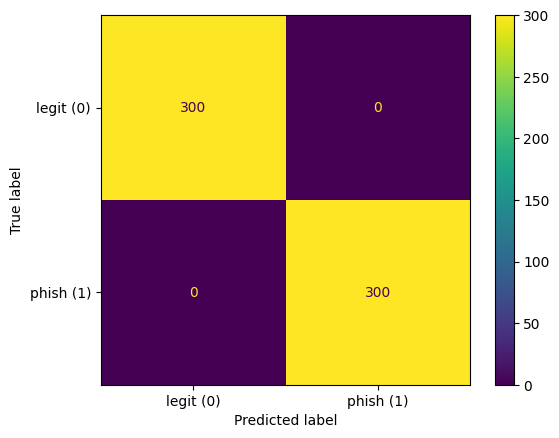

In [142]:
# XGBoost training
from xgboost import XGBClassifier
import numpy as np

# class weight equivalent for imbalance:
pos_weight = (y_train == 0).sum() / max(1, (y_train == 1).sum())

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEED,
    n_jobs=-1,
    scale_pos_weight=float(pos_weight),
    eval_metric="logloss"
)
xgb.fit(X_train, y_train)

eval_and_show(xgb, X_val, y_val, "Validation – XGBoost (balanced)")
eval_and_show(xgb, X_test, y_test, "Test – XGBoost (balanced)")
# joblib.dump(xgb, f"{OUTPUT_DIR}/model_xgboost.joblib")


In [143]:
# Comparing table
import pandas as pd

def get_row(name, model, Xv, yv):
    from sklearn.metrics import precision_recall_fscore_support, roc_auc_score
    yhat = model.predict(Xv)
    p, r, f1, _ = precision_recall_fscore_support(yv, yhat, average=None, zero_division=0)
    # index 1 = phishing
    row = {
        "Model": name,
        "Accuracy": (yhat == yv).mean(),
        "Phish_Precision": p[1],
        "Phish_Recall": r[1],
        "Phish_F1": f1[1],
    }
    if hasattr(model, "predict_proba"):
        row["ROC_AUC"] = roc_auc_score(yv, model.predict_proba(Xv)[:,1])
    else:
        row["ROC_AUC"] = None
    return row

models = [
    ("RandomForest (baseline)", rf),
    ("RandomForest (balanced)", rf_bal),
    ("DecisionTree", dt),
    ("NaiveBayes", nb),
    ("XGBoost", xgb),
]

comp = pd.DataFrame([get_row(n, m, X_test, y_test) for n,m in models])
comp.sort_values("Phish_F1", ascending=False).reset_index(drop=True)


,Model,Accuracy,Phish_Precision,Phish_Recall,Phish_F1,ROC_AUC
0,RandomForest (baseline),1.000000,1.0,1.000000,1.000000,1.000000
1,RandomForest (balanced),1.000000,1.0,1.000000,1.000000,1.000000
2,XGBoost,1.000000,1.0,1.000000,1.000000,1.000000
3,DecisionTree,0.998333,1.0,0.996667,0.998331,0.998333
4,NaiveBayes,0.998333,1.0,0.996667,0.998331,1.000000



=== Validation – RF (class_weight=balanced) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


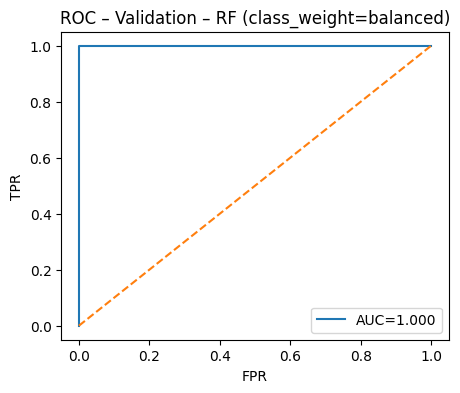


=== Test – RF (class_weight=balanced) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


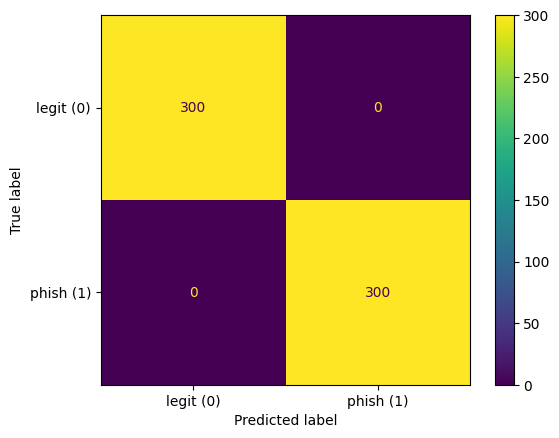

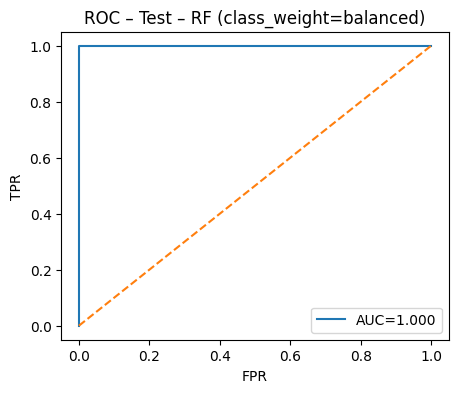

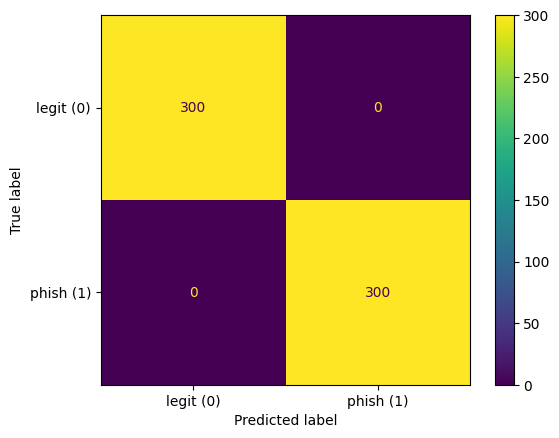

In [144]:
eval_and_show(rf_bal, X_val, y_val, "Validation – RF (class_weight=balanced)")
eval_and_show(rf_bal, X_test, y_test, "Test – RF (class_weight=balanced)")


In [145]:
!pip install beautifulsoup4 lxml



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [146]:
# Content based extraction
from bs4 import BeautifulSoup
import tldextract, time, math, re
from urllib.parse import urlparse

HDRS = {"User-Agent": "Mozilla/5.0 (Research; Non-Exec; Student)"}
TIMEOUT = 5
SLEEP = 0.0 
CONTENT_SAMPLE_PER_CLASS = 40

def domain_of(u):
    ext = tldextract.extract(u)
    return ".".join([p for p in [ext.domain, ext.suffix] if p])

EVENT_ATTRS = ["onclick","onload","onerror","onmouseover","onsubmit"]

def text_entropy(s):
    if not s: return 0.0
    from collections import Counter
    c = Counter(s)
    n = sum(c.values())
    probs = [v/n for v in c.values()]
    return -sum(p*math.log2(p) for p in probs)

def fetch_one(u):
    try:
        r = requests.get(u, headers=HDRS, timeout=TIMEOUT, allow_redirects=True)
        html = r.text
        soup = BeautifulSoup(html, "lxml")
        host = domain_of(u)

        # elements
        forms = soup.find_all("form")
        inputs = soup.find_all("input")
        pw = [i for i in inputs if i.get("type","").lower()=="password"]
        iframes = soup.find_all("iframe")
        scripts = soup.find_all("script")

        # links and external ratio
        links = [a.get("href") for a in soup.find_all("a", href=True)]
        links = [h for h in links if isinstance(h, str)]
        abs_links = []
        for h in links:
            try:
                if h.startswith("http"):
                    abs_links.append(h)
            except Exception:
                pass
        ext_links = [h for h in abs_links if domain_of(h) and domain_of(h) != host]
        ext_ratio = (len(ext_links) / len(abs_links)) if abs_links else 0.0

        # inline handlers / redirects / data URI
        handlers = sum(1 for tag in soup.find_all(True) for a in EVENT_ATTRS if tag.has_attr(a))
        meta_refresh = int(bool(soup.find("meta", attrs={"http-equiv": re.compile("refresh", re.I)})))
        data_uri = len(re.findall(r"src=['\"]data:", html, flags=re.I))
        has_window_loc = int("window.location" in html.lower())

        # page text signals
        text = soup.get_text(separator=" ", strip=True)[:20000].lower()
        tokens = re.split(r"\W+", text)
        avg_tok = (sum(len(t) for t in tokens)/len(tokens)) if tokens else 0.0
        susp_words = {"login","verify","update","secure","account","bank","confirm","password",
                      "signin","support","billing","limited","unlock","alert","notice","invoice",
                      "refund","apple","paypal","microsoft","office","outlook","amazon"}
        susp_text_hits = int(any(w in text for w in susp_words))

        return {
            "num_forms": len(forms),
            "num_inputs": len(inputs),
            "num_password": len(pw),
            "num_iframes": len(iframes),
            "num_scripts": len(scripts),
            "num_links": len(abs_links),
            "external_link_ratio": round(ext_ratio, 3),
            "inline_handlers": handlers,
            "meta_refresh": meta_refresh,
            "data_uri_count": data_uri,
            "has_window_location": has_window_loc,
            "text_entropy": round(text_entropy(text), 3),
            "avg_token_len": round(avg_tok, 3),
            "suspicious_text_hits": susp_text_hits,
        }
    except Exception:
        # on failure, return zeros so row is still usable
        return {
            "num_forms":0,"num_inputs":0,"num_password":0,"num_iframes":0,"num_scripts":0,
            "num_links":0,"external_link_ratio":0.0,"inline_handlers":0,"meta_refresh":0,
            "data_uri_count":0,"has_window_location":0,"text_entropy":0.0,"avg_token_len":0.0,
            "suspicious_text_hits":0
        }

def build_content_features(df_urls, per_class=CONTENT_SAMPLE_PER_CLASS):
    # balanced sample per class to limit network usage
    pos = df_urls[df_urls["label"]==1].sample(min(per_class, sum(df_urls["label"]==1)), random_state=SEED)
    neg = df_urls[df_urls["label"]==0].sample(min(per_class, sum(df_urls["label"]==0)), random_state=SEED)
    sample = pd.concat([pos, neg], ignore_index=True).copy()

    rows = []
    for r in sample.itertuples(index=False):
        feats = fetch_one(r.url)
        feats["url"] = r.url
        feats["label"] = r.label
        rows.append(feats)
        time.sleep(SLEEP)
    return pd.DataFrame(rows)

content_df = build_content_features(raw_df[["url","label"]], per_class=CONTENT_SAMPLE_PER_CLASS)
content_df.head()


,num_forms,num_inputs,num_password,num_iframes,num_scripts,num_links,external_link_ratio,inline_handlers,meta_refresh,data_uri_count,has_window_location,text_entropy,avg_token_len,suspicious_text_hits,url,label
0,0,0,0,0,6,0,0.000,1,0,0,0,3.978,4.083,0,http://photobucket.com/,1
1,0,12,0,0,35,110,1.000,0,0,1,1,4.432,5.825,1,http://mcafee.net/,1
2,0,0,0,1,54,248,0.052,0,0,1,1,4.732,5.574,0,http://banki.ru/,1
3,0,0,0,0,0,0,0.000,0,0,0,0,0.000,0.000,0,http://cdn-apple.com/,1
4,5,15,0,0,34,106,0.189,0,0,24,1,4.393,4.983,1,http://abebooks.com/,1


In [147]:
# Merge URL and content features for combined models
combined = feat_df.merge(content_df, on=["url","label"], how="left")
combined = combined.fillna(0)

# Define content-only columns
X_cols_content  = [c for c in content_df.columns if c not in ["url","label"]]
X_cols_combined = [c for c in combined.columns if c not in ["url","label","source"]]

# Create train/val/test matrices using original split indices
X_train_all = combined.loc[train.index, X_cols_combined]
X_val_all   = combined.loc[val.index,   X_cols_combined]
X_test_all  = combined.loc[test.index,  X_cols_combined]

print(f"✓ Created combined features:")
print(f"  - Content columns: {len(X_cols_content)}")
print(f"  - Combined columns: {len(X_cols_combined)}")
print(f"  - Training shape: {X_train_all.shape}")


✓ Created combined features:
  - Content columns: 14
  - Combined columns: 38
  - Training shape: (2800, 38)



=== Validation – Decision Tree (content-only) ===
              precision    recall  f1-score   support

           0     0.5034    1.0000    0.6696       300
           1     1.0000    0.0133    0.0263       300

    accuracy                         0.5067       600
   macro avg     0.7517    0.5067    0.3480       600
weighted avg     0.7517    0.5067    0.3480       600

ROC-AUC: 0.5067


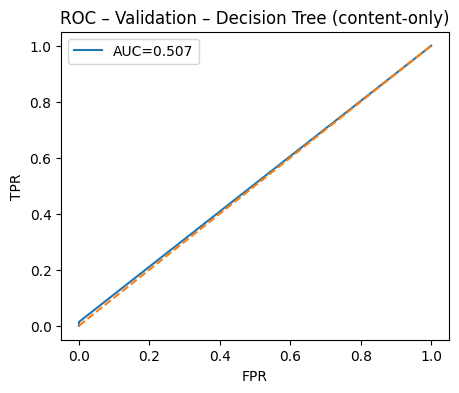


=== Test – Decision Tree (content-only) ===
              precision    recall  f1-score   support

           0     0.5051    0.9967    0.6704       300
           1     0.8750    0.0233    0.0455       300

    accuracy                         0.5100       600
   macro avg     0.6900    0.5100    0.3579       600
weighted avg     0.6900    0.5100    0.3579       600

ROC-AUC: 0.5116


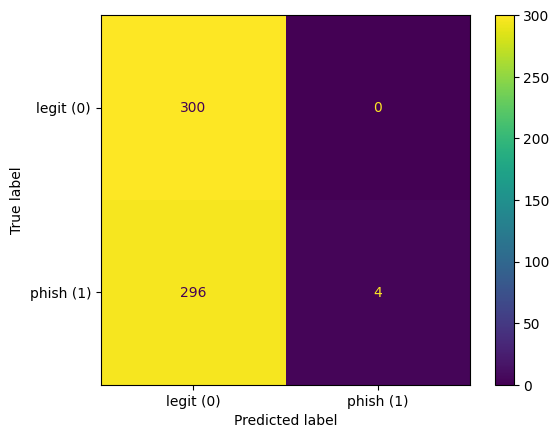

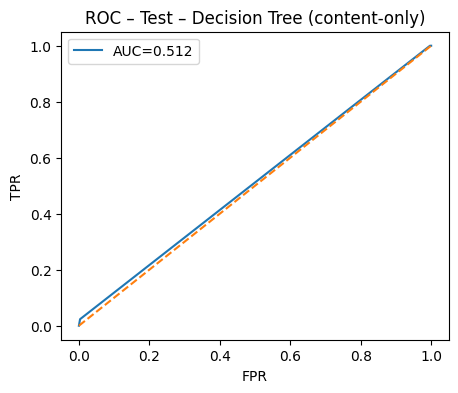

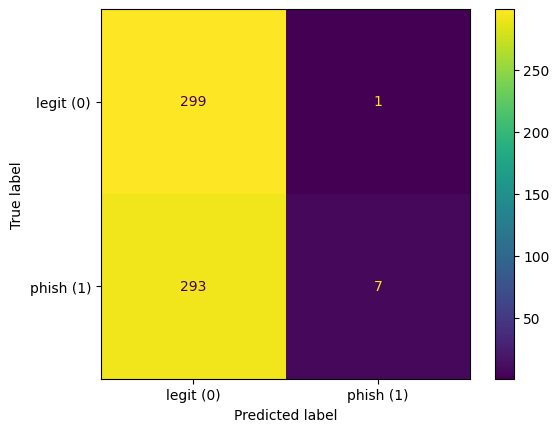

In [148]:
from sklearn.tree import DecisionTreeClassifier

dt_content = DecisionTreeClassifier(
    random_state=SEED,
    class_weight="balanced"
)
dt_content.fit(X_train_all[X_cols_content], y_train)

eval_and_show(dt_content, X_val_all[X_cols_content], y_val, "Validation – Decision Tree (content-only)")
eval_and_show(dt_content, X_test_all[X_cols_content], y_test,  "Test – Decision Tree (content-only)")



=== Validation – Naive Bayes (content-only) ===
              precision    recall  f1-score   support

           0     0.5034    1.0000    0.6696       300
           1     1.0000    0.0133    0.0263       300

    accuracy                         0.5067       600
   macro avg     0.7517    0.5067    0.3480       600
weighted avg     0.7517    0.5067    0.3480       600

ROC-AUC: 0.5067


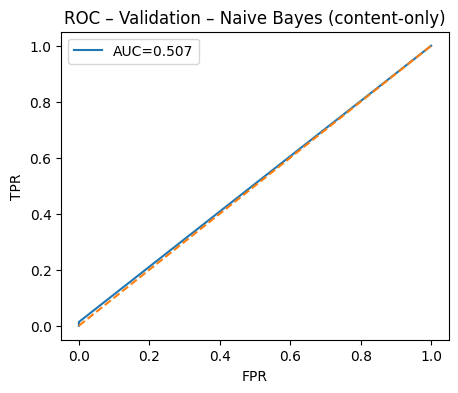


=== Test – Naive Bayes (content-only) ===
              precision    recall  f1-score   support

           0     0.5042    0.9933    0.6689       300
           1     0.7778    0.0233    0.0453       300

    accuracy                         0.5083       600
   macro avg     0.6410    0.5083    0.3571       600
weighted avg     0.6410    0.5083    0.3571       600

ROC-AUC: 0.5083


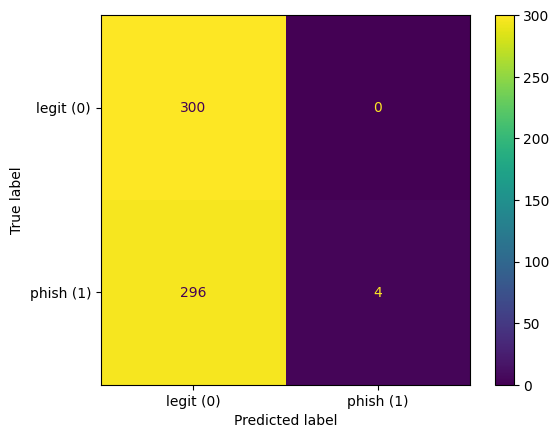

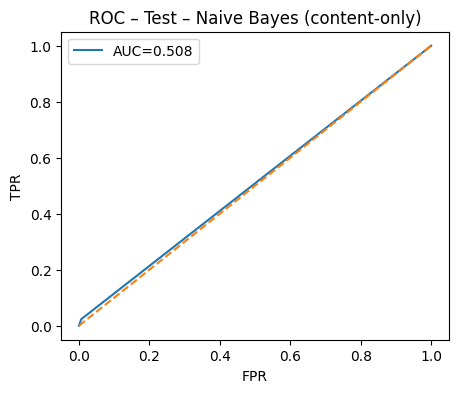

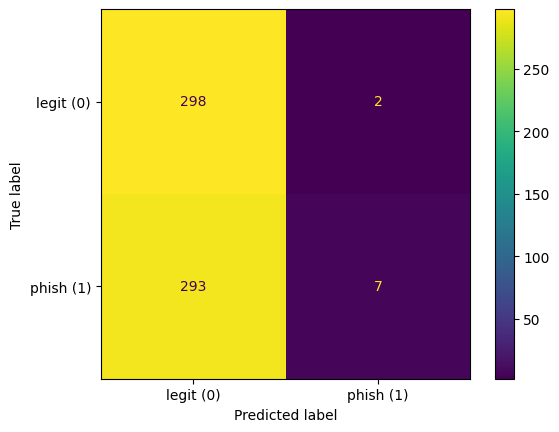

In [149]:
from sklearn.naive_bayes import GaussianNB

nb_content = GaussianNB()
nb_content.fit(X_train_all[X_cols_content], y_train)

eval_and_show(nb_content, X_val_all[X_cols_content], y_val, "Validation – Naive Bayes (content-only)")
eval_and_show(nb_content, X_test_all[X_cols_content], y_test,  "Test – Naive Bayes (content-only)")



=== Validation – XGBoost (content-only) ===
              precision    recall  f1-score   support

           0     0.5034    1.0000    0.6696       300
           1     1.0000    0.0133    0.0263       300

    accuracy                         0.5067       600
   macro avg     0.7517    0.5067    0.3480       600
weighted avg     0.7517    0.5067    0.3480       600

ROC-AUC: 0.5067


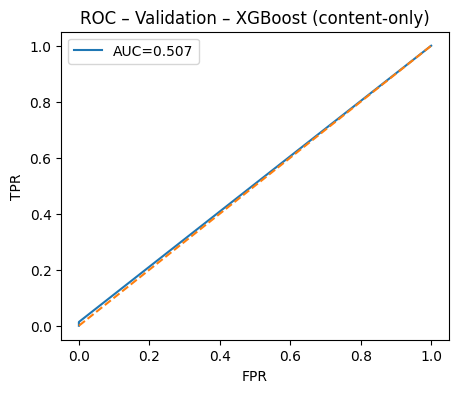


=== Test – XGBoost (content-only) ===
              precision    recall  f1-score   support

           0     0.5051    0.9967    0.6704       300
           1     0.8750    0.0233    0.0455       300

    accuracy                         0.5100       600
   macro avg     0.6900    0.5100    0.3579       600
weighted avg     0.6900    0.5100    0.3579       600

ROC-AUC: 0.5117


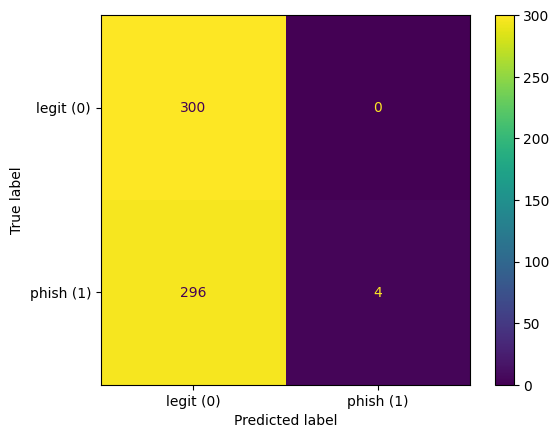

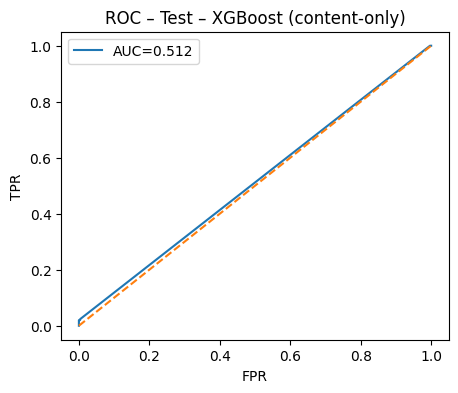

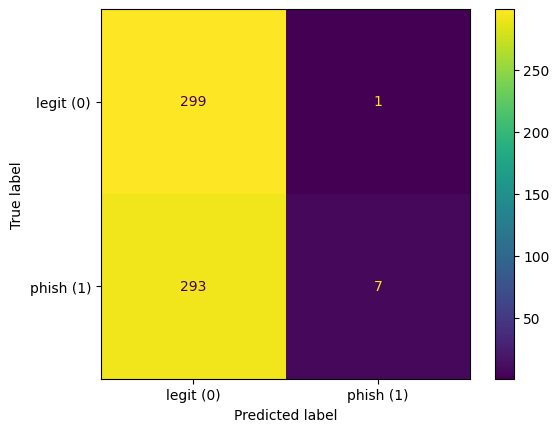

In [150]:
from xgboost import XGBClassifier

pos_weight_content = float((y_train == 0).sum()) / max(1, (y_train == 1).sum())

xgb_content = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEED,
    n_jobs=-1,
    scale_pos_weight=pos_weight_content,
    eval_metric="logloss"
)
xgb_content.fit(X_train_all[X_cols_content], y_train)

eval_and_show(xgb_content, X_val_all[X_cols_content], y_val, "Validation – XGBoost (content-only)")
eval_and_show(xgb_content, X_test_all[X_cols_content], y_test,  "Test – XGBoost (content-only)")



=== Validation – RF (content-only) ===
              precision    recall  f1-score   support

           0     0.5034    1.0000    0.6696       300
           1     1.0000    0.0133    0.0263       300

    accuracy                         0.5067       600
   macro avg     0.7517    0.5067    0.3480       600
weighted avg     0.7517    0.5067    0.3480       600

ROC-AUC: 0.5067


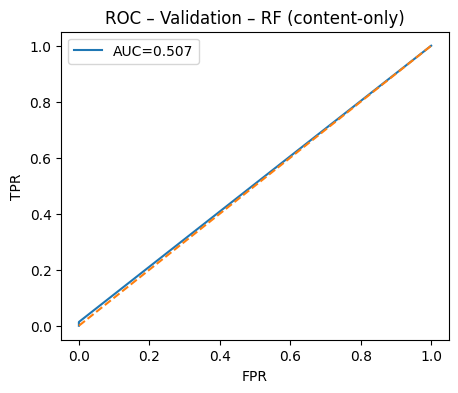


=== Test – RF (content-only) ===
              precision    recall  f1-score   support

           0     0.5042    0.9967    0.6697       300
           1     0.8571    0.0200    0.0391       300

    accuracy                         0.5083       600
   macro avg     0.6807    0.5083    0.3544       600
weighted avg     0.6807    0.5083    0.3544       600

ROC-AUC: 0.5083


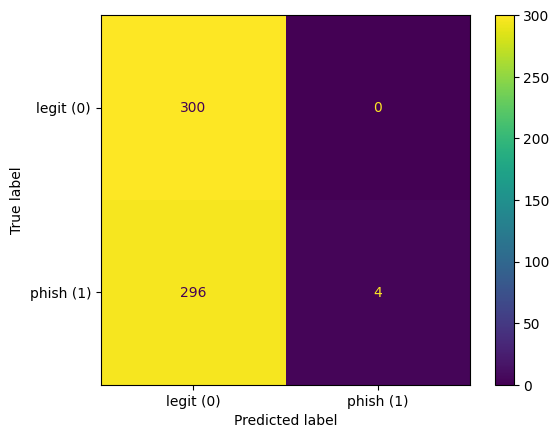

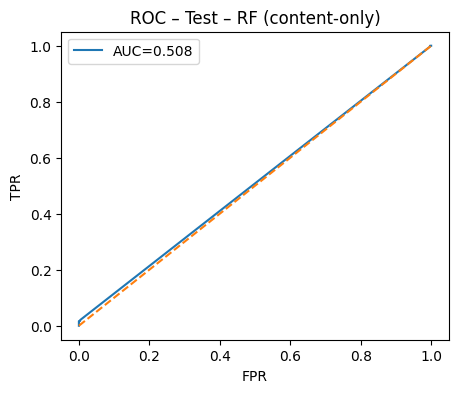

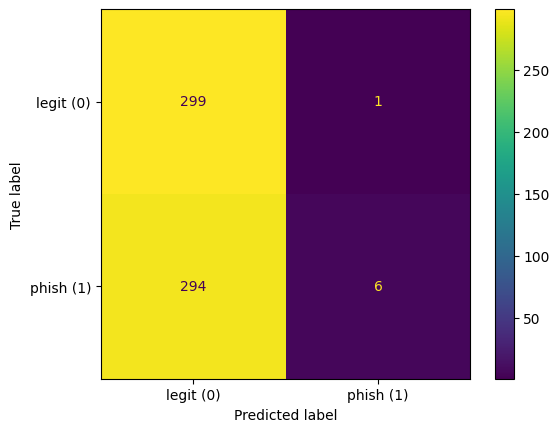

In [151]:
from sklearn.ensemble import RandomForestClassifier

rf_content = RandomForestClassifier(
    n_estimators=250,
    n_jobs=-1,
    random_state=SEED,
    class_weight="balanced"
)

rf_content.fit(X_train_all[X_cols_content], y_train)

eval_and_show(rf_content, X_val_all[X_cols_content], y_val, "Validation – RF (content-only)")
eval_and_show(rf_content, X_test_all[X_cols_content], y_test, "Test – RF (content-only)")


In [152]:
# Comparing table
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

def row_for(name, model):
    Xv = X_test_all[X_cols_content]
    yv = y_test
    yhat = model.predict(Xv)
    p, r, f1, _ = precision_recall_fscore_support(yv, yhat, average=None, zero_division=0)
    out = {
        "Model": name,
        "Accuracy": float((yhat == yv).mean()),
        "Phish_Precision": float(p[1]),
        "Phish_Recall": float(r[1]),
        "Phish_F1": float(f1[1]),
        "ROC_AUC": None
    }
    if hasattr(model, "predict_proba"):
        out["ROC_AUC"] = float(roc_auc_score(yv, model.predict_proba(Xv)[:,1]))
    return out

content_models = [
    ("RF (content)", rf_content),
    ("DecisionTree (content)", dt_content),
    ("NaiveBayes (content)", nb_content),
    ("XGBoost (content)", xgb_content),
]

content_comp = pd.DataFrame([row_for(n, m) for n, m in content_models]).sort_values("Phish_F1", ascending=False)
content_comp.reset_index(drop=True)


,Model,Accuracy,Phish_Precision,Phish_Recall,Phish_F1,ROC_AUC
0,DecisionTree (content),0.510000,0.875000,0.023333,0.045455,0.511628
1,XGBoost (content),0.510000,0.875000,0.023333,0.045455,0.511656
2,NaiveBayes (content),0.508333,0.777778,0.023333,0.045307,0.508333
3,RF (content),0.508333,0.857143,0.020000,0.039088,0.508333



=== Validation – XGBoost (combined URL+content) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


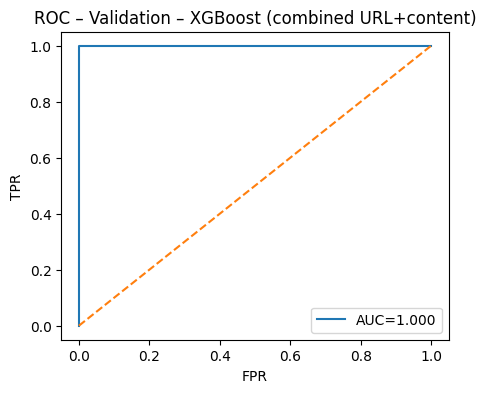


=== Test – XGBoost (combined URL+content) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


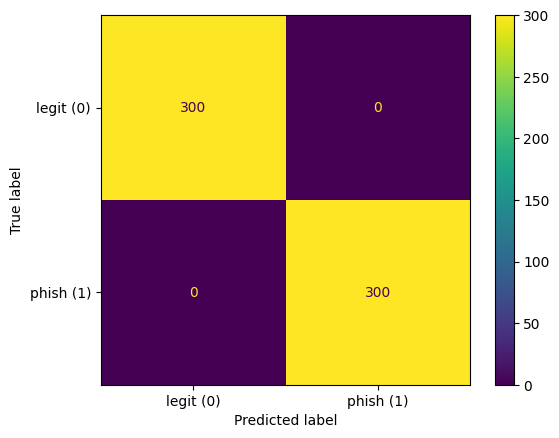

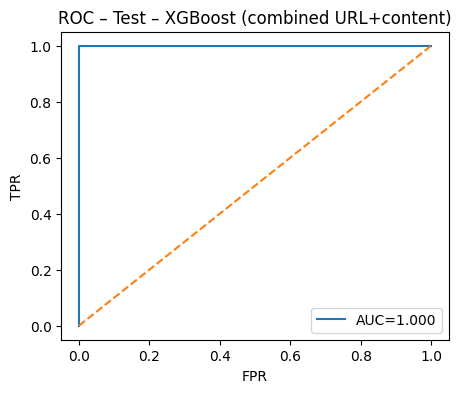

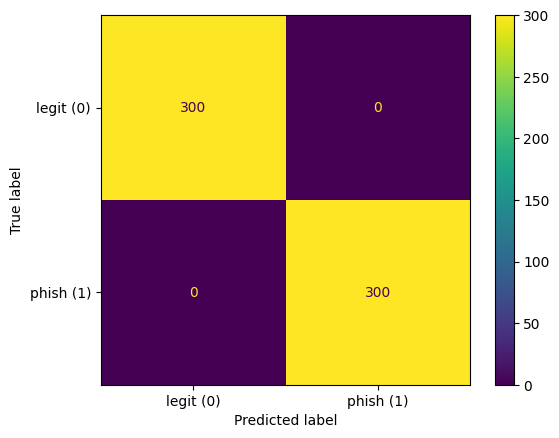

In [153]:
# Combined feature model using XGBoost (best overall ensemble style)
from xgboost import XGBClassifier

pos_weight_combined = float((y_train == 0).sum()) / max(1, (y_train == 1).sum())

xgb_combined = XGBClassifier(
    n_estimators=250,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEED,
    n_jobs=-1,
    scale_pos_weight=pos_weight_combined,
    eval_metric="logloss"
)
xgb_combined.fit(X_train_all, y_train)

# Evaluate
eval_and_show(xgb_combined, X_val_all, y_val, "Validation – XGBoost (combined URL+content)")
eval_and_show(xgb_combined, X_test_all, y_test, "Test – XGBoost (combined URL+content)")



=== Validation – RF (combined URL+content) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


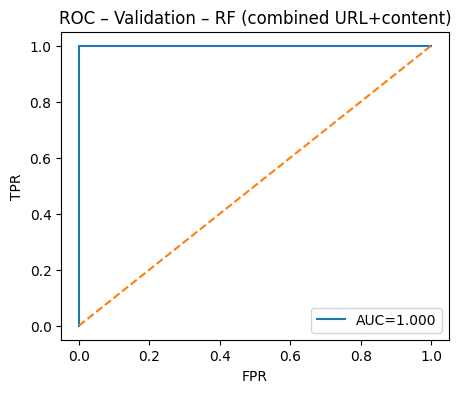


=== Test – RF (combined URL+content) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       300
           1     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600

ROC-AUC: 1.0


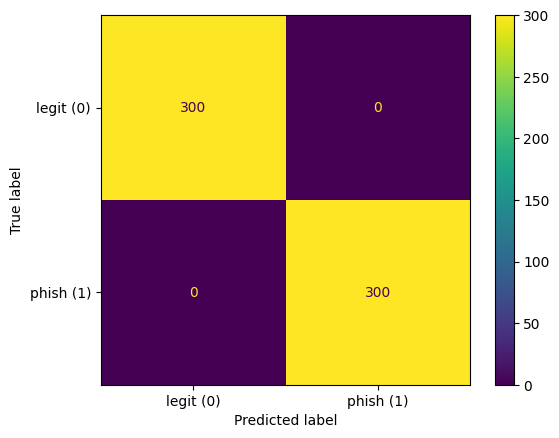

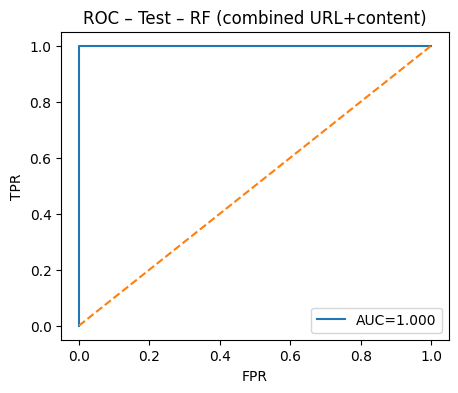

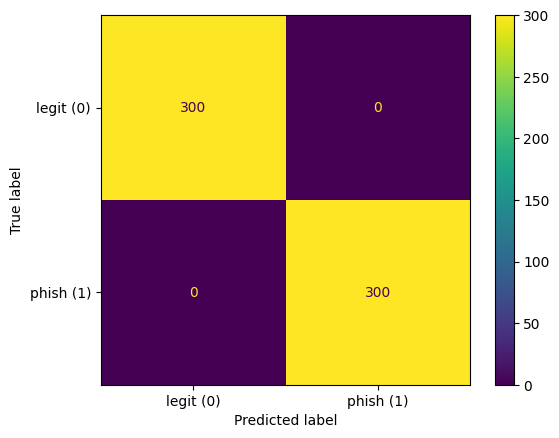

In [154]:
from sklearn.ensemble import RandomForestClassifier

rf_combined = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    n_jobs=-1,
    random_state=SEED,
    class_weight="balanced"
)

rf_combined.fit(X_train_all, y_train)

# Evaluate
eval_and_show(rf_combined, X_val_all, y_val, "Validation – RF (combined URL+content)")
eval_and_show(rf_combined, X_test_all, y_test, "Test – RF (combined URL+content)")


In [155]:
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

def get_row_final(name, model, Xv, yv):
    yhat = model.predict(Xv)
    p, r, f1, _ = precision_recall_fscore_support(yv, yhat, average=None, zero_division=0)
    row = {
        "Model": name,
        "Accuracy": (yhat == yv).mean(),
        "Phish_Precision": p[1],
        "Phish_Recall": r[1],
        "Phish_F1": f1[1],
        "ROC_AUC": None
    }
    if hasattr(model, "predict_proba"):
        row["ROC_AUC"] = roc_auc_score(yv, model.predict_proba(Xv)[:,1])
    return row

compare_final = pd.DataFrame([
    get_row_final("RF (URL-only)", rf, X_test, y_test),
    get_row_final("XGBoost (content-only)", xgb_content, X_test_all[X_cols_content], y_test),
    get_row_final("XGBoost (combined)", xgb_combined, X_test_all, y_test),
    get_row_final("RF (combined)", rf_combined, X_test_all, y_test),
])

compare_final


,Model,Accuracy,Phish_Precision,Phish_Recall,Phish_F1,ROC_AUC
0,RF (URL-only),1.00,1.000,1.000000,1.000000,1.000000
1,XGBoost (content-only),0.51,0.875,0.023333,0.045455,0.511656
2,XGBoost (combined),1.00,1.000,1.000000,1.000000,1.000000
3,RF (combined),1.00,1.000,1.000000,1.000000,1.000000


# Clean Evaluation Tables (Balanced vs Imbalanced)



In [156]:
# --- Configuration for clean evaluation ---
SEED = 42
BAL_PHISH = 2000
BAL_BENIGN = 2000
IMB_PHISH = 2000   # will cap to available phishing
IMB_BENIGN = 6000  # larger benign pool for imbalance

# algorithms to evaluate
ALGOS = ["RF", "DT", "NB", "XGB"]

# metrics to report
METRICS = ["Accuracy", "Phish_Precision", "Phish_Recall", "Phish_F1", "ROC_AUC"]


In [157]:
# --- Helpers: dataset builder and model factory ---
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

def build_dataset(n_phish, n_benign, seed=SEED):
    ph = get_phishing_urls().drop_duplicates("url")
    ph = ph.sample(n=min(n_phish, len(ph)), random_state=seed)
    be = get_tranco(n=n_benign*3).drop_duplicates("url")
    be = be.sample(n=min(n_benign, len(be)), random_state=seed)
    df = pd.concat([ph, be], ignore_index=True).dropna(subset=["url"]).drop_duplicates("url")
    return df

def split_df(df, label_col="label", seed=SEED):
    train_val, test = train_test_split(df, test_size=0.15, stratify=df[label_col], random_state=seed)
    val_ratio = 0.15 / (1 - 0.15)
    train, val = train_test_split(train_val, test_size=val_ratio, stratify=train_val[label_col], random_state=seed)
    return train, val, test

def make_models(seed=SEED):
    models = {}
    models["RF"] = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed, class_weight="balanced")
    models["DT"] = DecisionTreeClassifier(random_state=seed, class_weight="balanced")
    try:
        from sklearn.naive_bayes import GaussianNB
        models["NB"] = GaussianNB()
    except Exception:
        pass
    try:
        from xgboost import XGBClassifier
        models["XGB"] = XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.1,
            subsample=0.9, colsample_bytree=0.9, random_state=seed,
            n_jobs=-1, eval_metric="logloss"
        )
    except Exception:
        pass
    return models

def eval_model(model, Xv, yv):
    yhat = model.predict(Xv)
    p, r, f1, _ = precision_recall_fscore_support(yv, yhat, average=None, zero_division=0)
    row = {
        "Accuracy": float((yhat == yv).mean()),
        "Phish_Precision": float(p[1]) if len(p) > 1 else 0.0,
        "Phish_Recall": float(r[1]) if len(r) > 1 else 0.0,
        "Phish_F1": float(f1[1]) if len(f1) > 1 else 0.0,
    }
    if hasattr(model, "predict_proba"):
        try:
            row["ROC_AUC"] = float(roc_auc_score(yv, model.predict_proba(Xv)[:,1]))
        except Exception:
            row["ROC_AUC"] = None
    else:
        row["ROC_AUC"] = None
    return row


In [158]:
# --- Build datasets ---
balanced_df = build_dataset(BAL_PHISH, BAL_BENIGN)
imbalanced_df = build_dataset(IMB_PHISH, IMB_BENIGN)

print("Balanced counts:", balanced_df["label"].value_counts().to_dict())
print("Imbalanced counts:", imbalanced_df["label"].value_counts().to_dict())


Balanced counts: {0: 2000, 1: 2000}
Imbalanced counts: {1: 6000, 0: 2000}


In [159]:
# --- Feature builders ---
def build_url_features(df):
    rows = []
    for row in df.itertuples(index=False):
        feats = url_features(row.url)
        feats["url"] = row.url
        feats["label"] = row.label
        feats["source"] = getattr(row, "source", "")
        rows.append(feats)
    return pd.DataFrame(rows)

def build_content_df(df):
    return build_content_features(df[["url", "label"]], per_class=CONTENT_SAMPLE_PER_CLASS)

def merge_url_content(url_df, content_df):
    combined = url_df.merge(content_df, on=["url", "label"], how="left")
    return combined


In [160]:
# --- Evaluation runner ---
def evaluate_block(df_raw, label):
    results = []
    # URL-only
    url_df = build_url_features(df_raw)
    X_cols = [c for c in url_df.columns if c not in ["url", "label", "source"]]
    train, val, test = split_df(url_df)
    X_train, y_train = train[X_cols], train["label"]
    X_test, y_test = test[X_cols], test["label"]

    models = make_models()
    for name, model in models.items():
        # for XGB, set scale_pos_weight for imbalance
        if name == "XGB":
            try:
                pos = (y_train == 0).sum()
                neg = (y_train == 1).sum()
                model.set_params(scale_pos_weight=float(pos) / max(1, neg))
            except Exception:
                pass
        model.fit(X_train, y_train)
        row = eval_model(model, X_test, y_test)
        row.update({"Dataset": label, "Approach": "URL", "Model": name})
        results.append(row)

    # Content-only
    content_df = build_content_df(df_raw)
    content_df = content_df.fillna(0)
    Xc = [c for c in content_df.columns if c not in ["url", "label"]]
    train, val, test = split_df(content_df)
    X_train, y_train = train[Xc], train["label"]
    X_test, y_test = test[Xc], test["label"]

    models = make_models()
    for name, model in models.items():
        if name == "XGB":
            try:
                pos = (y_train == 0).sum()
                neg = (y_train == 1).sum()
                model.set_params(scale_pos_weight=float(pos) / max(1, neg))
            except Exception:
                pass
        model.fit(X_train, y_train)
        row = eval_model(model, X_test, y_test)
        row.update({"Dataset": label, "Approach": "Content", "Model": name})
        results.append(row)

    # Combined
    combined_df = merge_url_content(url_df, content_df)
    combined_df = combined_df.fillna(0)
    X_all = [c for c in combined_df.columns if c not in ["url", "label", "source"]]
    train, val, test = split_df(combined_df)
    X_train, y_train = train[X_all], train["label"]
    X_test, y_test = test[X_all], test["label"]

    models = make_models()
    for name, model in models.items():
        if name == "XGB":
            try:
                pos = (y_train == 0).sum()
                neg = (y_train == 1).sum()
                model.set_params(scale_pos_weight=float(pos) / max(1, neg))
            except Exception:
                pass
        model.fit(X_train, y_train)
        row = eval_model(model, X_test, y_test)
        row.update({"Dataset": label, "Approach": "Combined", "Model": name})
        results.append(row)

    return pd.DataFrame(results)

balanced_table = evaluate_block(balanced_df, "Balanced")
imbalanced_table = evaluate_block(imbalanced_df, "Imbalanced")

balanced_table


,Accuracy,Phish_Precision,Phish_Recall,Phish_F1,ROC_AUC,Dataset,Approach,Model
0,1.000000,1.0,1.000000,1.000000,1.000000,Balanced,URL,RF
1,1.000000,1.0,1.000000,1.000000,1.000000,Balanced,URL,DT
2,0.998333,1.0,0.996667,0.998331,1.000000,Balanced,URL,NB
3,1.000000,1.0,1.000000,1.000000,1.000000,Balanced,URL,XGB
4,0.916667,1.0,0.833333,0.909091,0.930556,Balanced,Content,RF
5,0.833333,1.0,0.666667,0.800000,0.777778,Balanced,Content,DT
6,0.750000,1.0,0.500000,0.666667,0.902778,Balanced,Content,NB
7,0.916667,1.0,0.833333,0.909091,0.930556,Balanced,Content,XGB
8,1.000000,1.0,1.000000,1.000000,1.000000,Balanced,Combined,RF
9,1.000000,1.0,1.000000,1.000000,1.000000,Balanced,Combined,DT


In [161]:
imbalanced_table


,Accuracy,Phish_Precision,Phish_Recall,Phish_F1,ROC_AUC,Dataset,Approach,Model
0,1.000000,1.0,1.000000,1.000000,1.000000,Imbalanced,URL,RF
1,1.000000,1.0,1.000000,1.000000,1.000000,Imbalanced,URL,DT
2,0.999167,1.0,0.998889,0.999444,1.000000,Imbalanced,URL,NB
3,1.000000,1.0,1.000000,1.000000,1.000000,Imbalanced,URL,XGB
4,0.750000,1.0,0.500000,0.666667,0.791667,Imbalanced,Content,RF
5,0.750000,1.0,0.500000,0.666667,0.791667,Imbalanced,Content,DT
6,0.750000,1.0,0.500000,0.666667,0.708333,Imbalanced,Content,NB
7,0.750000,1.0,0.500000,0.666667,0.791667,Imbalanced,Content,XGB
8,1.000000,1.0,1.000000,1.000000,1.000000,Imbalanced,Combined,RF
9,1.000000,1.0,1.000000,1.000000,1.000000,Imbalanced,Combined,DT


In [162]:
# --- Best of best (by Accuracy) ---
def best_of_best(df):
    idx = df.groupby(["Dataset", "Approach"])["Accuracy"].idxmax()
    return df.loc[idx].sort_values(["Dataset", "Approach"]).reset_index(drop=True)

best_table = best_of_best(pd.concat([balanced_table, imbalanced_table], ignore_index=True))
best_table


,Accuracy,Phish_Precision,Phish_Recall,Phish_F1,ROC_AUC,Dataset,Approach,Model
0,1.000000,1.0,1.000000,1.000000,1.000000,Balanced,Combined,RF
1,0.916667,1.0,0.833333,0.909091,0.930556,Balanced,Content,RF
2,1.000000,1.0,1.000000,1.000000,1.000000,Balanced,URL,RF
3,1.000000,1.0,1.000000,1.000000,1.000000,Imbalanced,Combined,RF
4,0.750000,1.0,0.500000,0.666667,0.791667,Imbalanced,Content,RF
5,1.000000,1.0,1.000000,1.000000,1.000000,Imbalanced,URL,RF
